In [40]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

from quantify_core.data.handling import (
    load_dataset,
    set_datadir,
    default_datadir,
)

In [2]:
set_datadir(default_datadir())

Data will be saved in:
/home/pschaefers/quantify-data


In [3]:
def process_CMAES_data(dataset, popsize, n_qubits, qubits = None):
    """
    Processes fidelity data for n qubits based on the given dataset and population size.

    Parameters:
        dataset: An object containing data attributes (e.g., dataset.x0.data, dataset.y0.data, etc.).
        popsize: The size of the population.
        n_qubits: The number of qubits.

    Returns:
        A dictionary containing mean and population fidelity data for all qubits and shared parameters.
    """

    if qubits is None:
        if hasattr(dataset, "elements"):
            qubits = dataset.elements
        else:
            raise ValueError("No qubits provided and dataset has no 'elements' attribute.")
        
    # Extract parameters shared across all qubits
    shared_data = {
        'objective': dataset.y0.data,
    }

    # Initialize dictionary to hold data for each qubit
    fidelity_data = {'shared': shared_data}

    for q in range(n_qubits):
        # Start index for each qubit's fidelity data (y1 onwards, 6 values per qubit)
        start_idx = 1 + q* 6
        # Extract fidelity data for the current qubit
        fidelity_data[qubits[q]] = {
            'freq': getattr(dataset, f'x{q*3}').data,
            'ampl': getattr(dataset, f'x{q*3 + 1}').data,
            'dur': getattr(dataset, f'x{q*3 + 2}').data,            
            'assignfid_av': getattr(dataset, f'y{start_idx}').data,
            'assignfid_01': getattr(dataset, f'y{start_idx + 1}').data,
            'assignfid_02': getattr(dataset, f'y{start_idx + 2}').data,
            'assignfid_12': getattr(dataset, f'y{start_idx + 3}').data,
            'qndfid': getattr(dataset, f'y{start_idx + 4}').data,
            'qndpifid': getattr(dataset, f'y{start_idx + 5}').data,
        }

        #Extract data of the mean
        fidelity_data[qubits[q]]['mean'] = {
            key: fidelity_data[qubits[q]][key][popsize::popsize + 1]
            for key in ['freq','ampl', 'dur', 'assignfid_av', 'assignfid_01', 'assignfid_02', 'assignfid_12', 'qndfid', 'qndpifid']
        }

        # Extract data of the population
        fidelity_data[qubits[q]]['pop'] = {
            key: np.array([
                fidelity_data[qubits[q]][key][i::popsize+1]
                for i in range(popsize)
            ])
            for key in ['freq','ampl', 'dur', 'assignfid_av', 'assignfid_01', 'assignfid_02', 'assignfid_12', 'qndfid', 'qndpifid']
        }


    return fidelity_data

/tmp/ipykernel_1441/3695184796.py:79: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


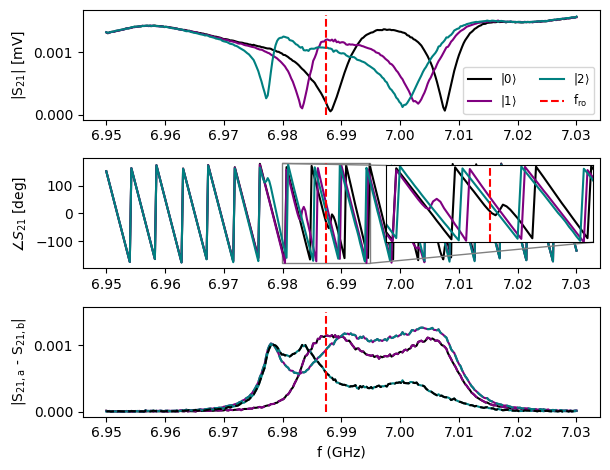

In [63]:
tuid = "20250731-124753-661-8d46e7"
SpecData = load_dataset(tuid)

tuid = "20250219-051837-501-9abe02"
data = load_dataset(tuid)
popsize = 20
n_qubits = 1
CMAESData = process_CMAES_data(data, popsize, n_qubits, ["D1"])

mean_readout_frequency = CMAESData['D1']['mean']['freq'][-1]*1e-9

repetitions = 301
freq0 = SpecData.x0.data[:repetitions]*1e-9
freq1 = SpecData.x0.data[repetitions:repetitions*2]*1e-9
freq2 = SpecData.x0.data[repetitions*2:]*1e-9

magn0 = SpecData.y0.data[:repetitions]
magn1 = SpecData.y0.data[repetitions:repetitions*2]
magn2 = SpecData.y0.data[repetitions*2:]

phase0 = SpecData.y1.data[:repetitions]
phase1 = SpecData.y1.data[repetitions:repetitions*2]
phase2 = SpecData.y1.data[repetitions*2:]

compl_0 = magn0*np.exp(np.deg2rad(phase0)*1j)
compl_1 = magn1*np.exp(np.deg2rad(phase1)*1j)
compl_2 = magn2*np.exp(np.deg2rad(phase2)*1j)

S21_01 = np.abs(compl_0 - compl_1)
S21_02 = np.abs(compl_0 - compl_2)
S21_12 = np.abs(compl_1 - compl_2)

fig, axes = plt.subplots(ncols=1, nrows=3)
ax1 = axes[0]
ax2 = axes[1]
ax3 = axes[2]

fig.set_size_inches(6.2,4.8)

ax1.plot(freq0, magn0, label = r'$|0\rangle$', color="black")
ax1.plot(freq1, magn1, label=r'$|1\rangle$', color="purple")
ax1.plot(freq2, magn2, label=r'$|2\rangle$', color="teal")
ax1.vlines(mean_readout_frequency,0,0.0016,ls="--",color="red", label=r"f$_\mathrm{ro}$")
ax1.set_ylabel(r"|S$_{21}$| [mV]") 
ax1.legend(ncols=2,loc='lower right',fontsize="small")

ax2.plot(freq0, phase0, label = r'$|0\rangle$', color="black")
ax2.plot(freq1, phase1, label=r'$|1\rangle$', color="purple")
ax2.plot(freq2, phase2, label=r'$|2\rangle$', color="teal")
ax2.vlines(mean_readout_frequency,-180,180,ls="--",color="red", label=r"f$_\mathrm{ro}$")
ax2.set_ylabel(r"$\angle S_{21}$ [deg]") 

inset_ax = inset_axes(ax2, width="40%", height="70%", loc="upper right")
inset_ax.plot(freq0, phase0, color="black")
inset_ax.plot(freq1, phase1, color="purple")
inset_ax.plot(freq2, phase2, color="teal")
inset_ax.vlines(mean_readout_frequency,-180,180,ls="--",color="red")
inset_ax.set_xlim(mean_readout_frequency-0.0075, mean_readout_frequency+0.0075)
inset_ax.set_ylim(-180, 180)
inset_ax.set_xticks([])
inset_ax.set_yticks([])

mark_inset(ax2, inset_ax, loc1=2, loc2=4, fc="none", ec="0.5")

ax3.plot(freq0, S21_01, label = r"|S$_{21,01}$|", color="black")
ax3.plot(freq0, S21_02, label = r"|S$_{21,02}$|", color="purple")
ax3.plot(freq0, S21_12, label = r"|S$_{21,12}$|", color="teal")

ax3.plot(freq0, S21_01, label = r"|S$_{21,01}$|", color="purple", ls="dashed")
ax3.plot(freq0, S21_02, label = r"|S$_{21,02}$|", color="teal", ls="dashed")
ax3.plot(freq0, S21_12, label = r"|S$_{21,12}$|", color="black", ls="dashed")

ax3.vlines(mean_readout_frequency, 0, 0.0015, ls="--",color="red")
ax3.set_xlabel("f (GHz)")
ax3.set_ylabel(r"|S$_{21,\mathrm{a}}$ - S$_{21,\mathrm{b}}$|")

plt.tight_layout()
plt.show()

(301,)


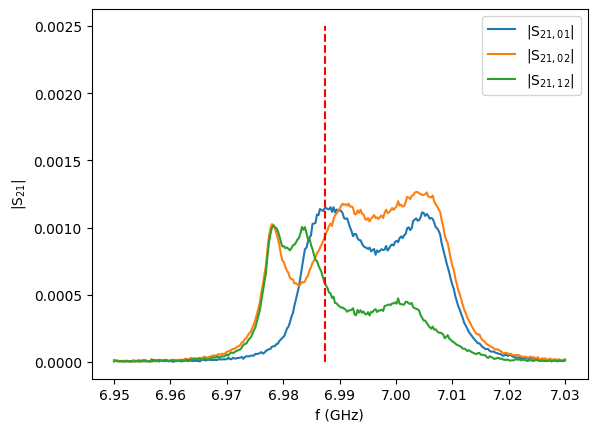

In [39]:
compl_0 = magn0*np.exp(np.deg2rad(phase0)*1j)
compl_1 = magn1*np.exp(np.deg2rad(phase1)*1j)
compl_2 = magn2*np.exp(np.deg2rad(phase2)*1j)
print(compl_0.shape)

# fig, ax = plt.subplots()
# ax.plot(
#     compl_0.real,
#     compl_0.imag,
#     linestyle='-',
#     marker='.',
# )

# plt.show()

S21_01 = np.abs(compl_0 - compl_1)
S21_02 = np.abs(compl_0 - compl_2)
S21_12 = np.abs(compl_1 - compl_2)

plt.plot(freq0, S21_01, label = r"|S$_{21,01}$|")
plt.plot(freq0, S21_02, label = r"|S$_{21,02}$|")
plt.plot(freq0, S21_12, label = r"|S$_{21,12}$|")
plt.vlines(mean_readout_frequency, 0, 0.0025, ls="--",color="red")
plt.xlabel("f (GHz)")
plt.ylabel(r"|S$_{21}$|")
plt.legend()
plt.show()